# Formative 2 — Task 3: Sound Data Processing & Voiceprint Verification Model

**Owner:** Ketia
**Scope:** Task 3 (sound data collection and processing) + the voiceprint verification model from Task 4.

This notebook:
1. Loads 2 recorded phrases per group member ("Yes, approve" and "Confirm transaction"), plus at least one voice from outside the group for the unauthorized-attempt case.
2. Displays each recording as a waveform and a spectrogram.
3. Applies 3 augmentations per sample (pitch shift, time stretch, background noise).
4. Extracts MFCCs, spectral roll-off, RMS energy and other features and saves them to `audio_features.csv`.
5. Trains and evaluates a voiceprint verification model (accuracy, F1, log loss).
6. Saves the model and a `voice_model.py` module with `verify_voice(path)` for the CLI app (Task 6).

### File naming
Name every recording `<member>_<phrase>.<ext>` (lowercase, no spaces), for example:

| File | Meaning |
|---|---|
| `ketia_approve.wav` | Ketia saying "Yes, approve" |
| `ketia_confirm.wav` | Ketia saying "Confirm transaction" |
| `unknown1_approve.wav` | A voice from outside the group (unauthorized) |

Any file whose member name starts with `unknown` is labeled `unknown`. Supported formats: `.wav`, `.mp3`, `.m4a`, `.ogg`, `.flac`.

## 1. Setup

In [1]:
# librosa is preinstalled on Colab; this line only makes sure it is there.
!pip install -q librosa soundfile

import os, glob, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import soundfile as sf
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

SR = 16000                       # sample rate used for every recording
AUDIO_DIR = "audio"              # raw recordings
AUG_DIR = "audio_augmented"      # augmented copies are written here
os.makedirs(AUDIO_DIR, exist_ok=True)
os.makedirs(AUG_DIR, exist_ok=True)

## 2. Get the recordings
The group's 8 recordings are stored in the repo's `audio/` folder:

| Original phone file | Stored as | Original format |
|---|---|---|
| `Ketia_approve.m4a` | `ketia_approve.flac` | AAC, 48 kHz stereo |
| `Ketia_comfirm.m4a` | `ketia_confirm.flac` | AAC, 48 kHz stereo |
| `Audric_approve.m4a` | `audric_approve.flac` | AAC, 48 kHz stereo |
| `Audric_confirm.m4a` | `audric_confirm.flac` | AAC, 48 kHz stereo |
| `Twariq_approve.aac` | `twariq_approve.flac` | AAC, 44.1 kHz mono |
| `Twariq_confirm.aac` | `twariq_confirm.flac` | AAC, 44.1 kHz mono |
| `another_person_approve.mp4` | `unknown1_approve.flac` | AAC, 44.1 kHz mono |
| `another_person_comfirm.mp4` | `unknown1_confirm.flac` | AAC, 44.1 kHz mono |

Before storing, the files were renamed to the `<member>_<phrase>` convention (lowercase, the typo `comfirm` fixed, the outside voice renamed to `unknown1`) and converted to 16 kHz mono lossless FLAC so that recordings from different phones share one format.

**Running in Colab:** run the cell below. If the `audio/` folder is empty, it asks you to upload the recordings — `audio.zip`, the 8 `.flac` files, or the original phone files. Phone file names are normalized automatically (lowercase, `comfirm` → `confirm`, `another person` → `unknown1`).

In [2]:
import zipfile, shutil

AUDIO_EXTS = (".wav", ".mp3", ".m4a", ".aac", ".mp4", ".ogg", ".flac")

def clean_name(filename):
    """Normalize a phone file name to '<member>_<phrase>.<ext>'.
    'Ketia_comfirm.m4a' -> 'ketia_confirm.m4a'; 'another person_approve.mp4' -> 'unknown1_approve.mp4'"""
    stem, ext = os.path.splitext(os.path.basename(filename))
    stem = stem.lower().strip().replace(" ", "_").replace("-", "_").replace("comfirm", "confirm")
    member, _, phrase = stem.rpartition("_")
    if member.startswith("another"):
        member = "unknown1"
    return f"{member}_{phrase}{ext.lower()}"

def audio_files_in(folder):
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(AUDIO_EXTS))

def save_audio(name, data):
    path = os.path.join(AUDIO_DIR, clean_name(name))
    with open(path, "wb") as f:
        f.write(data)
    print(f"  {name}  ->  {os.path.basename(path)}")

if not audio_files_in(AUDIO_DIR):
    try:
        from google.colab import files
        print("Select the 8 recordings (or audio.zip):")
        uploaded = files.upload()
        for name, data in uploaded.items():
            if name.lower().endswith(".zip"):
                with open(name, "wb") as f:
                    f.write(data)
                with zipfile.ZipFile(name) as z:
                    for member in z.namelist():
                        if member.lower().endswith(AUDIO_EXTS):
                            save_audio(member, z.read(member))
            elif name.lower().endswith(AUDIO_EXTS):
                save_audio(name, data)
            else:
                print(f"  Skipped '{name}' — not an audio file")
    except ImportError:
        print(f"Put the recordings in the '{AUDIO_DIR}/' folder next to this notebook.")

# Normalize any names already in the folder as well
for f in audio_files_in(AUDIO_DIR):
    if clean_name(f) != f:
        shutil.move(os.path.join(AUDIO_DIR, f), os.path.join(AUDIO_DIR, clean_name(f)))

found = audio_files_in(AUDIO_DIR)
print(f"\n{len(found)} recordings in '{AUDIO_DIR}/':", found)
if len(found) != 8:
    print("⚠️  Expected 8 recordings (2 per member + 2 from the outside voice). Check what was uploaded.")

Select the 8 recordings (or audio.zip):


Saving another person_approve.mp4 to another person_approve.mp4
Saving another person_comfirm.mp4 to another person_comfirm.mp4
Saving Audric_approve.m4a to Audric_approve.m4a
Saving Audric_confirm.m4a to Audric_confirm.m4a
Saving Ketia_approve.m4a to Ketia_approve.m4a
Saving Ketia_comfirm.m4a to Ketia_comfirm.m4a
Saving Twariq_approve.aac to Twariq_approve.aac
Saving Twariq_confirm.aac to Twariq_confirm.aac
  another person_approve.mp4  ->  unknown1_approve.mp4
  another person_comfirm.mp4  ->  unknown1_confirm.mp4
  Audric_approve.m4a  ->  audric_approve.m4a
  Audric_confirm.m4a  ->  audric_confirm.m4a
  Ketia_approve.m4a  ->  ketia_approve.m4a
  Ketia_comfirm.m4a  ->  ketia_confirm.m4a
  Twariq_approve.aac  ->  twariq_approve.aac
  Twariq_confirm.aac  ->  twariq_confirm.aac

8 recordings in 'audio/': ['audric_approve.m4a', 'audric_confirm.m4a', 'ketia_approve.m4a', 'ketia_confirm.m4a', 'twariq_approve.aac', 'twariq_confirm.aac', 'unknown1_approve.mp4', 'unknown1_confirm.mp4']


## 3. Load and clean the recordings
Each file is loaded as mono at 16 kHz, silence at the start and end is trimmed (`top_db=25`), and the amplitude is peak-normalized so that loud and quiet recordings are comparable.

In [3]:
EXTS = AUDIO_EXTS
PHRASES = {"approve": "Yes, approve", "confirm": "Confirm transaction"}

def parse_name(path):
    """'ketia_approve.wav' -> ('ketia', 'approve')."""
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    member, _, phrase = stem.rpartition("_")
    return member, phrase

def label_for(member):
    return "unknown" if member.startswith("unknown") else member

import subprocess, tempfile

def load_audio(path, sr=SR):
    """Load any audio file as mono at `sr`. Phone formats (.m4a, .aac, .mp4) that the
    audio library cannot open directly are converted with ffmpeg first."""
    try:
        y, _ = librosa.load(path, sr=sr, mono=True)
    except Exception:
        with tempfile.NamedTemporaryFile(suffix=".wav") as tmp:
            subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", path, "-vn", "-ac", "1",
                            "-ar", str(sr), tmp.name], check=True)
            y, _ = librosa.load(tmp.name, sr=sr, mono=True)
    return y

def load_clean(path, sr=SR):
    y = load_audio(path, sr)
    y, _ = librosa.effects.trim(y, top_db=25)
    peak = np.max(np.abs(y))
    return y / peak if peak > 0 else y

files_found = sorted(f for f in glob.glob(os.path.join(AUDIO_DIR, "*"))
                     if f.lower().endswith(EXTS))
assert files_found, f"No audio files found in '{AUDIO_DIR}'. Upload them first (section 2)."

import hashlib
recordings, seen = [], {}
for path in files_found:
    member, phrase = parse_name(path)
    y = load_clean(path)
    # Duplicate check: identical audio content under two file names
    digest = hashlib.md5(np.round(y, 5).tobytes()).hexdigest()
    if digest in seen:
        print(f"⚠️  DUPLICATE: '{os.path.basename(path)}' is identical to '{seen[digest]}' — dropped.")
        continue
    seen[digest] = os.path.basename(path)
    recordings.append({"file": os.path.basename(path), "member": member,
                       "label": label_for(member), "phrase": phrase,
                       "duration_s": round(len(y) / SR, 2), "signal": y})

rec_df = pd.DataFrame(recordings).drop(columns="signal")
display(rec_df)
print("\nRecordings per label:")
print(rec_df["label"].value_counts())

,file,member,label,phrase,duration_s
0,audric_approve.m4a,audric,audric,approve,1.44
1,audric_confirm.m4a,audric,audric,confirm,1.95
2,ketia_approve.m4a,ketia,ketia,approve,1.25
3,ketia_confirm.m4a,ketia,ketia,confirm,2.59
4,twariq_approve.aac,twariq,twariq,approve,0.96
5,twariq_confirm.aac,twariq,twariq,confirm,1.22
6,unknown1_approve.mp4,unknown1,unknown,approve,1.31
7,unknown1_confirm.mp4,unknown1,unknown,confirm,1.70



Recordings per label:
label
audric     2
ketia      2
twariq     2
unknown    2
Name: count, dtype: int64


**Duplicate check.** The outside voice first arrived as the same recording sent twice under two names. A duplicate would mean the model is tested on a clip it was trained on, which inflates the score, so the loader compares the audio content of every file and drops exact copies. The duplicate was replaced with the real "Yes, approve" recording before embedding, so all 8 recordings are now distinct.

### Listen to each recording

In [4]:
from IPython.display import Audio, display as ipy_display
for r in recordings:
    print(f"{r['file']}  ({r['duration_s']} s)")
    ipy_display(Audio(r["signal"], rate=SR))

audric_approve.m4a  (1.44 s)


audric_confirm.m4a  (1.95 s)


ketia_approve.m4a  (1.25 s)


ketia_confirm.m4a  (2.59 s)


twariq_approve.aac  (0.96 s)


twariq_confirm.aac  (1.22 s)


unknown1_approve.mp4  (1.31 s)


unknown1_confirm.mp4  (1.7 s)


**Data check.** Every member should have exactly 2 recordings (`approve` and `confirm`). Durations should be roughly 1–3 seconds after trimming. A much longer clip usually means background noise was not trimmed, so re-record it.

In [5]:
# Flag members who are missing a phrase
check = rec_df[rec_df.label != "unknown"].pivot_table(
    index="member", columns="phrase", values="file", aggfunc="count", fill_value=0)
display(check)
missing = check[(check < 1).any(axis=1)]
print("All members have both phrases." if missing.empty else f"Missing phrases for: {list(missing.index)}")

phrase,approve,confirm
member,,
audric,1,1
ketia,1,1
twariq,1,1


All members have both phrases.


## 4. Visualize: waveform and spectrogram for each recording

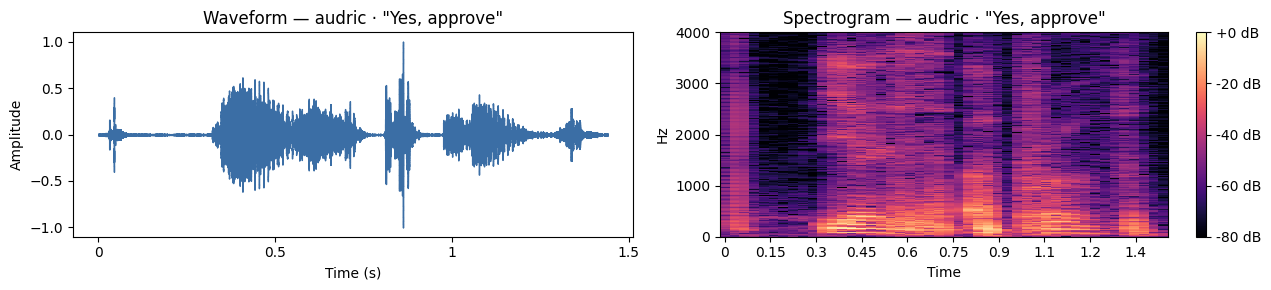

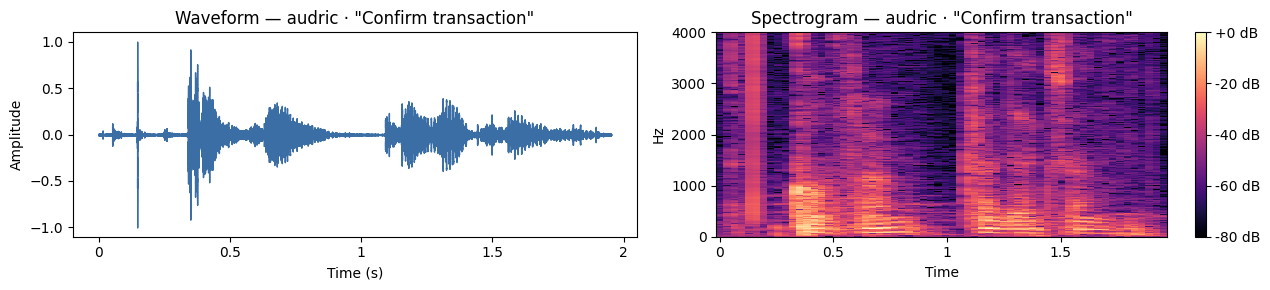

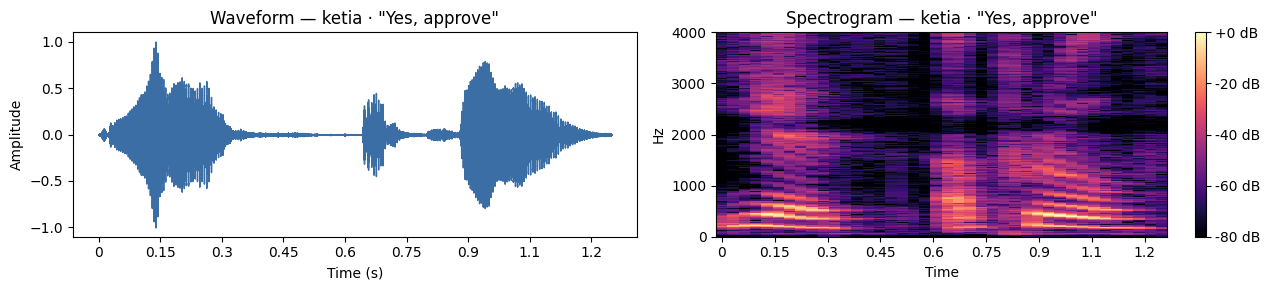

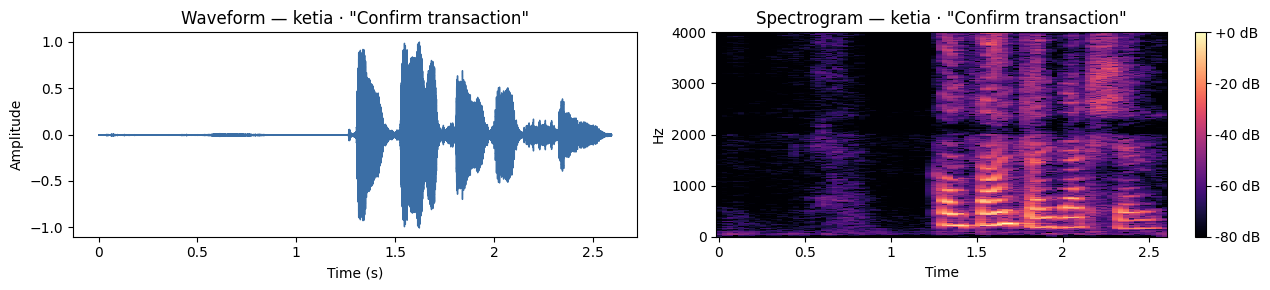

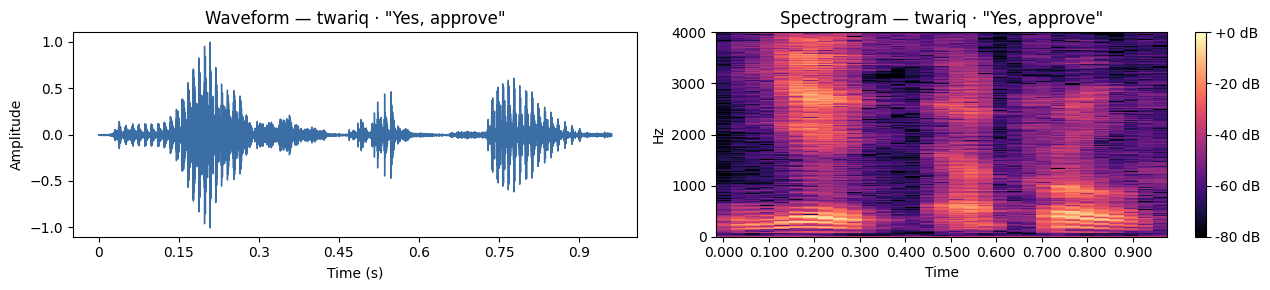

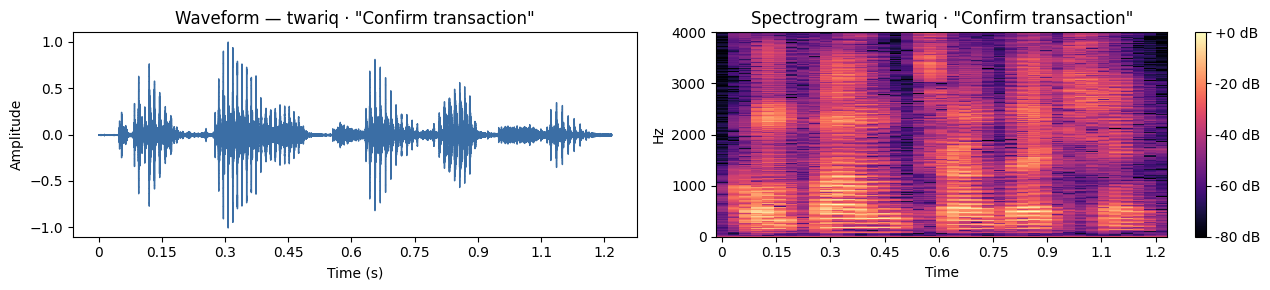

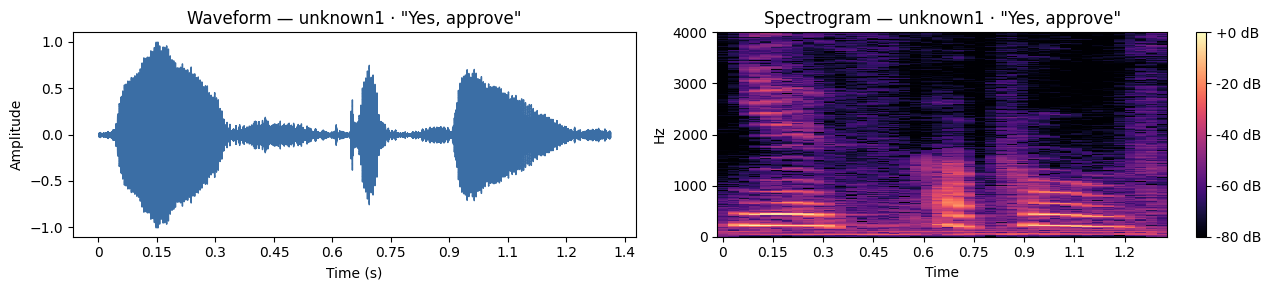

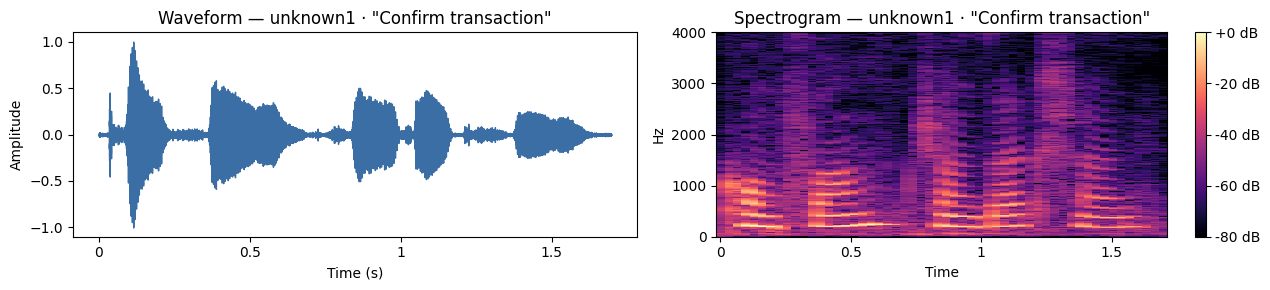

In [6]:
def plot_wave_and_spec(y, title, sr=SR):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3))
    librosa.display.waveshow(y, sr=sr, ax=axes[0], color="#3b6ea5")
    axes[0].set(title=f"Waveform — {title}", xlabel="Time (s)", ylabel="Amplitude")
    S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    img = librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="hz", ax=axes[1], cmap="magma")
    axes[1].set(title=f"Spectrogram — {title}", ylim=(0, 4000))
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
    plt.tight_layout()
    plt.show()

for r in recordings:
    plot_wave_and_spec(r["signal"], f"{r['member']} · \"{PHRASES.get(r['phrase'], r['phrase'])}\"")

### Interpretation
- **Waveforms:** each recording shows separate bursts of energy, one per word or syllable. In Ketia's "Yes, approve" there are three clear bursts — "Yes" (0–0.35 s), the short "a-" (≈0.65 s) and "prove" (0.9–1.2 s) — with near-flat silence between them, which means a clean recording. Twariq's version is faster (0.96 s vs 1.25 s) and has a small amount of background noise visible between words. "Confirm transaction" clips are longer than "Yes, approve" for every speaker (more syllables).
- **Spectrograms:** most speech energy sits below about 1 kHz, where the bright horizontal lines (harmonics of the voice's pitch) appear. The spacing of those lines and the position of the strongest bands differ between speakers — that is the voice "fingerprint" the MFCCs capture. The "s" sound in "Yes" shows up as a vertical patch of energy between 2 and 3.5 kHz, which is the same for everyone and therefore carries little speaker information.
- **Recording conditions:** the files came from different phones (48 kHz stereo `.m4a` and 44.1 kHz mono `.aac`/`.mp4`). Converting them all to 16 kHz mono puts them on the same footing.

## 5. Augmentation
Each original recording gets 3 augmented versions:

| Augmentation | Setting | Why |
|---|---|---|
| Pitch shift | +2 semitones | The same person can speak higher or lower on different days |
| Time stretch | 1.15× speed | People say the phrase faster or slower |
| Background noise | white noise at SNR ≈ 20 dB | Recordings happen in noisy places |

That gives 4 versions per recording (original + 3). Augmented clips are also saved as `.wav` files in `audio_augmented/`.

In [7]:
def add_noise(y, snr_db=20):
    rng = np.random.default_rng(RANDOM_STATE)
    signal_power = np.mean(y ** 2)
    noise_power = signal_power / (10 ** (snr_db / 10))
    return y + rng.normal(0, np.sqrt(noise_power), len(y))

AUGMENTATIONS = {
    "pitch_shift": lambda y: librosa.effects.pitch_shift(y, sr=SR, n_steps=2),
    "time_stretch": lambda y: librosa.effects.time_stretch(y, rate=1.15),
    "noise": lambda y: add_noise(y, snr_db=20),
}

samples = []   # every original + augmented clip
for r in recordings:
    base = {"member": r["member"], "label": r["label"], "phrase": r["phrase"], "source_file": r["file"]}
    samples.append({**base, "augmentation": "original", "signal": r["signal"]})
    for aug_name, fn in AUGMENTATIONS.items():
        y_aug = fn(r["signal"])
        out = os.path.join(AUG_DIR, f"{os.path.splitext(r['file'])[0]}_{aug_name}.wav")
        sf.write(out, y_aug, SR)
        samples.append({**base, "augmentation": aug_name, "signal": y_aug})

print(f"{len(recordings)} originals -> {len(samples)} total clips "
      f"({len(AUGMENTATIONS)} augmentations each)")

8 originals -> 32 total clips (3 augmentations each)


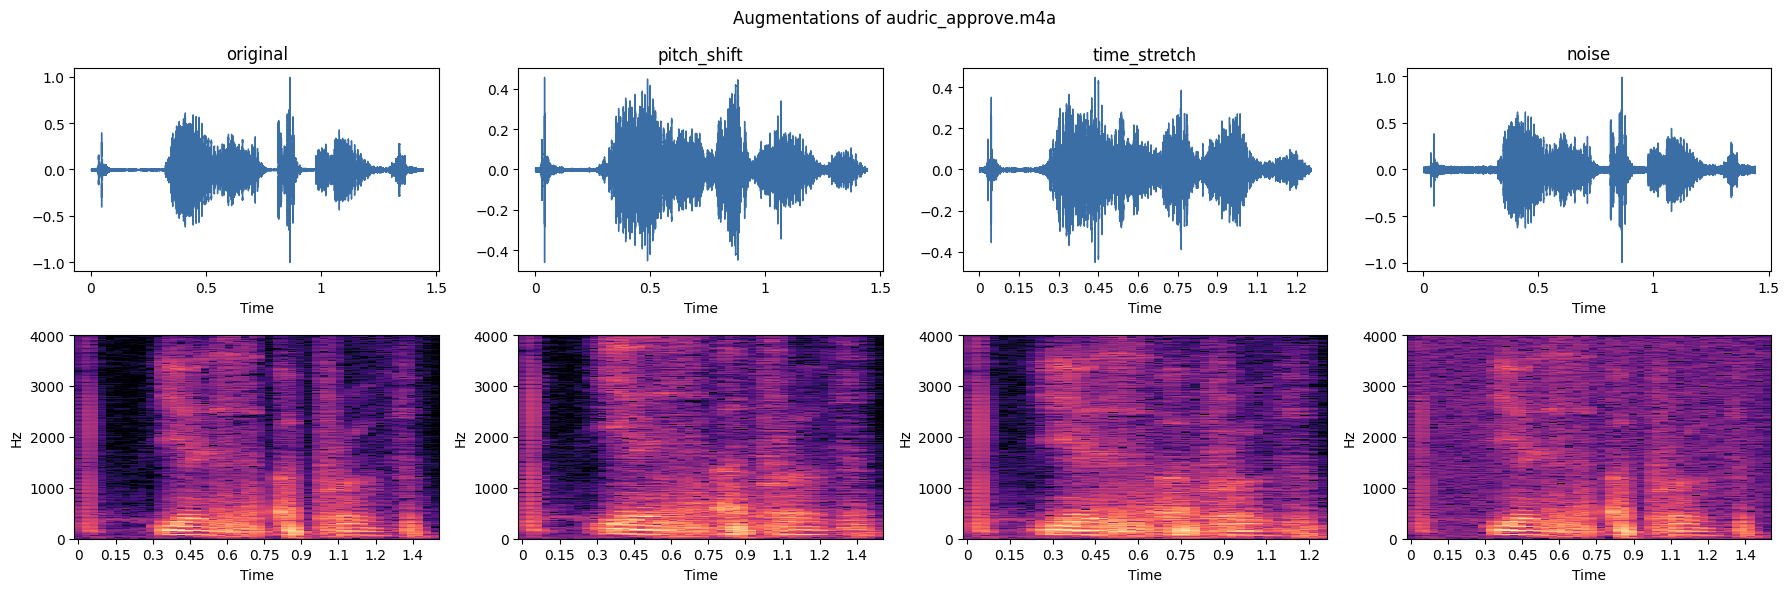

In [8]:
# Compare one recording with its 3 augmented versions
example = samples[0]["source_file"]
group = [s for s in samples if s["source_file"] == example]
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for i, s in enumerate(group):
    librosa.display.waveshow(s["signal"], sr=SR, ax=axes[0, i], color="#3b6ea5")
    axes[0, i].set_title(s["augmentation"])
    S_db = librosa.amplitude_to_db(np.abs(librosa.stft(s["signal"])), ref=np.max)
    librosa.display.specshow(S_db, sr=SR, x_axis="time", y_axis="hz", ax=axes[1, i], cmap="magma")
    axes[1, i].set_ylim(0, 4000)
fig.suptitle(f"Augmentations of {example}")
plt.tight_layout()
plt.show()

**What changed:** pitch shift moves the harmonic bands up; time stretch makes the clip shorter without changing pitch; noise fills the gaps between words with a light haze. In each version the overall shape of the phrase stays the same, so the speaker is still recognizable.

## 6. Feature extraction
The feature code is written to `voice_model.py` so that **training and the CLI app use exactly the same features**. Teammates can import `verify_voice` from this file in Task 6.

Features per clip (all summarized as mean and standard deviation over time):
- **MFCC 1–13:** the shape of the vocal tract — the main speaker-identity feature
- **Spectral roll-off:** frequency below which 85% of the energy lies (brightness of the voice)
- **RMS energy:** loudness
- **Spectral centroid:** the "center of mass" of the spectrum
- **Zero-crossing rate:** how noisy or breathy the signal is
- **Duration**

In [9]:
%%writefile voice_model.py
"""Voiceprint verification module (Formative 2, Task 3/4).

Usage in the CLI app:
    from voice_model import verify_voice
    member, confidence, approved = verify_voice("some_recording.wav")
"""
import subprocess
import tempfile

import numpy as np
import librosa
import joblib

SR = 16000
N_MFCC = 13
MODEL_PATH = "voice_model.joblib"
THRESHOLD = 0.70   # minimum confidence needed to approve (see notebook section 9)


def load_audio(path, sr=SR):
    """Load any audio file as mono at `sr`; phone formats are converted with ffmpeg if needed."""
    try:
        y, _ = librosa.load(path, sr=sr, mono=True)
    except Exception:
        with tempfile.NamedTemporaryFile(suffix=".wav") as tmp:
            subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", path, "-vn", "-ac", "1",
                            "-ar", str(sr), tmp.name], check=True)
            y, _ = librosa.load(tmp.name, sr=sr, mono=True)
    return y


def load_clean(path, sr=SR):
    y = load_audio(path, sr)
    y, _ = librosa.effects.trim(y, top_db=25)
    peak = np.max(np.abs(y))
    return y / peak if peak > 0 else y


def extract_features(y, sr=SR):
    """Return a dict of audio features for one clip."""
    feats = {}
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    for i in range(N_MFCC):
        feats[f"mfcc{i + 1}_mean"] = float(mfcc[i].mean())
        feats[f"mfcc{i + 1}_std"] = float(mfcc[i].std())
    frame_feats = {
        "rolloff": librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)[0],
        "rms_energy": librosa.feature.rms(y=y)[0],
        "centroid": librosa.feature.spectral_centroid(y=y, sr=sr)[0],
        "zcr": librosa.feature.zero_crossing_rate(y)[0],
    }
    for name, values in frame_feats.items():
        feats[f"{name}_mean"] = float(values.mean())
        feats[f"{name}_std"] = float(values.std())
    feats["duration_s"] = len(y) / sr
    return feats


def verify_voice(path, model_path=MODEL_PATH, threshold=THRESHOLD):
    """Return (predicted_member, confidence, approved).

    Access is approved only if the prediction is a known member AND
    the model's confidence is at least `threshold`.
    """
    bundle = joblib.load(model_path)
    model, columns = bundle["model"], bundle["feature_columns"]
    feats = extract_features(load_clean(path))
    x = np.array([[feats[c] for c in columns]])
    proba = model.predict_proba(x)[0]
    best = int(np.argmax(proba))
    member, confidence = model.classes_[best], float(proba[best])
    approved = member != "unknown" and confidence >= threshold
    return member, confidence, approved


if __name__ == "__main__":
    import sys
    m, c, ok = verify_voice(sys.argv[1])
    print(f"Predicted: {m} (confidence {c:.2f}) -> {'APPROVED' if ok else 'ACCESS DENIED'}")

Writing voice_model.py


In [10]:
import importlib, voice_model
importlib.reload(voice_model)
from voice_model import extract_features, verify_voice, THRESHOLD

rows = []
for s in samples:
    feats = extract_features(s["signal"])
    rows.append({"member": s["member"], "label": s["label"], "phrase": s["phrase"],
                 "augmentation": s["augmentation"], "source_file": s["source_file"], **feats})

audio_features = pd.DataFrame(rows)
audio_features.to_csv("audio_features.csv", index=False)
print("Saved audio_features.csv with shape", audio_features.shape)
audio_features.head()

Saved audio_features.csv with shape (32, 40)


,member,label,phrase,augmentation,source_file,mfcc1_mean,mfcc1_std,mfcc2_mean,mfcc2_std,mfcc3_mean,...,mfcc13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std,centroid_mean,centroid_std,zcr_mean,zcr_std,duration_s
0,audric,audric,approve,original,audric_approve.m4a,-205.169800,110.508759,114.974251,42.210571,22.050732,...,5.870914,3215.183424,1712.010244,0.098722,0.069466,1391.551431,669.951825,0.067351,0.030144,1.440000
1,audric,audric,approve,pitch_shift,audric_approve.m4a,-217.777405,99.906433,112.487610,36.929710,24.769228,...,7.073492,3404.721467,1788.963576,0.066378,0.044310,1449.340694,649.700442,0.075397,0.030089,1.440000
2,audric,audric,approve,time_stretch,audric_approve.m4a,-219.501755,90.888649,113.567848,37.639648,24.545673,...,4.524153,3179.492188,1657.184369,0.067587,0.039599,1368.514658,636.506784,0.066187,0.028064,1.252188
3,audric,audric,approve,noise,audric_approve.m4a,-128.753432,52.254593,63.259898,34.639141,31.168971,...,5.439465,5099.524457,1445.956300,0.100390,0.067939,2368.801928,892.212001,0.202679,0.119497,1.440000
4,audric,audric,confirm,original,audric_confirm.m4a,-218.781097,93.061012,109.531258,52.805424,16.893906,...,7.554963,3151.083669,1738.551477,0.066523,0.050468,1533.005332,923.583818,0.089804,0.060483,1.952000


## 7. Feature exploration

In [11]:
META = ["member", "label", "phrase", "augmentation", "source_file"]
FEATURE_COLS = [c for c in audio_features.columns if c not in META]

print("Missing values:", audio_features[FEATURE_COLS].isna().sum().sum())
print("Duplicate rows:", audio_features.duplicated(subset=FEATURE_COLS).sum())
display(audio_features.groupby("label")[["mfcc1_mean", "mfcc2_mean", "rolloff_mean",
                                          "rms_energy_mean", "centroid_mean"]].mean().round(2))

Missing values: 0
Duplicate rows: 0


,mfcc1_mean,mfcc2_mean,rolloff_mean,rms_energy_mean,centroid_mean
label,,,,,
audric,-201.66,98.32,3717.10,0.07,1716.11
ketia,-262.32,80.72,3589.45,0.09,1858.35
twariq,-192.38,87.70,3655.70,0.07,2016.14
unknown,-210.33,103.63,3504.17,0.11,1774.03


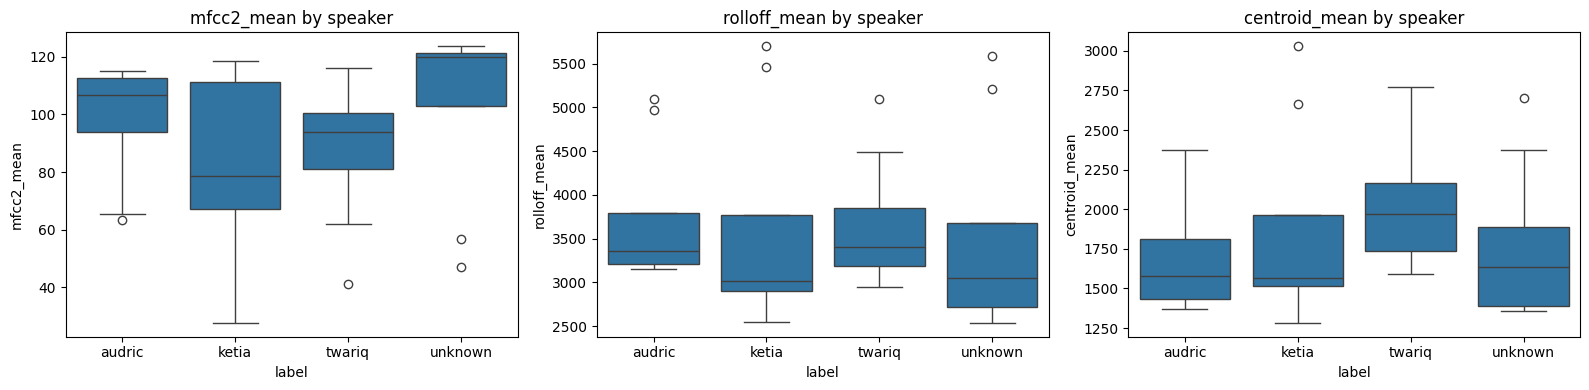

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["mfcc2_mean", "rolloff_mean", "centroid_mean"]):
    sns.boxplot(data=audio_features, x="label", y=col, ax=ax)
    ax.set_title(f"{col} by speaker")
plt.tight_layout()
plt.show()

**Reading the plots:** the boxes overlap heavily for spectral roll-off and spectral centroid, so those features alone cannot tell speakers apart — they change more with the phrase and the augmentation than with the person. MFCC 2 separates speakers better (the outside voice sits highest, Ketia lowest), and the few outliers in each box are the noise-augmented copies. This motivates the feature choice in section 8.1.

## 8. Train and evaluate the voiceprint model

**Honest evaluation — leave-one-recording-out.** Augmented copies of a recording are nearly identical to the original. If an original sat in training and its noisy copy sat in testing, accuracy would look falsely perfect. So each fold holds out **one original recording together with all its augmented copies**, trains on everything else, and predicts the held-out clips. Every clip gets predicted exactly once by a model that never heard that recording.

**Metrics:** accuracy, macro F1 (treats every speaker equally), and log loss (penalizes confident wrong answers — lower is better).

In [13]:
y = audio_features["label"].values
groups = audio_features["source_file"].values
CLASSES = np.unique(y)

def make_model(kind="rf"):
    clf = (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE) if kind == "rf"
           else LogisticRegression(max_iter=2000, C=0.5))
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])

def evaluate(cols, kind="rf"):
    """Leave-one-recording-out evaluation. Returns out-of-fold probabilities and predictions."""
    X = audio_features[cols].values
    proba = np.zeros((len(y), len(CLASSES)))
    for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups):
        m = make_model(kind).fit(X[train_idx], y[train_idx])
        idx = [np.where(CLASSES == c)[0][0] for c in m.classes_]   # align columns to all classes
        proba[np.ix_(test_idx, idx)] = m.predict_proba(X[test_idx])
    proba = (proba + 1e-6) / (proba + 1e-6).sum(axis=1, keepdims=True)
    return proba, CLASSES[proba.argmax(axis=1)]

### 8.1 Choosing features and model
All features are saved in `audio_features.csv`, but not all of them describe *who* is speaking:

- **MFCC 1** mostly measures overall loudness, which depends on how close the phone was to the mouth.
- **Standard deviations, roll-off, energy and duration** change with the phrase, the microphone and the background noise.
- **MFCC 2–13 means** describe the average shape of the vocal tract (the timbre of the voice), which is the classic feature set for speaker recognition.

The cell below compares both feature sets with two models.

In [14]:
MFCC_SPEAKER = [f"mfcc{i}_mean" for i in range(2, 14)]
feature_sets = {"All 39 features": FEATURE_COLS, "MFCC 2-13 means": MFCC_SPEAKER}
rows = []
for set_name, cols in feature_sets.items():
    for kind, model_name in [("rf", "Random Forest"), ("lr", "Logistic Regression")]:
        proba, pred = evaluate(cols, kind)
        rows.append({"features": set_name, "model": model_name,
                     "accuracy": accuracy_score(y, pred),
                     "F1 (macro)": f1_score(y, pred, average="macro"),
                     "log loss": log_loss(y, proba, labels=CLASSES)})
comparison = pd.DataFrame(rows).round(3)
display(comparison)

,features,model,accuracy,F1 (macro),log loss
0,All 39 features,Random Forest,0.312,0.333,1.152
1,All 39 features,Logistic Regression,0.500,0.497,0.994
2,MFCC 2-13 means,Random Forest,0.781,0.787,0.706
3,MFCC 2-13 means,Logistic Regression,0.781,0.787,0.647


### 8.2 Final model: Logistic Regression on MFCC 2–13 means
This combination scored best on all three metrics in the comparison above, so it is the model used for verification.

In [15]:
MODEL_FEATURES = MFCC_SPEAKER
oof_proba, oof_pred = evaluate(MODEL_FEATURES, "lr")

acc = accuracy_score(y, oof_pred)
f1 = f1_score(y, oof_pred, average="macro")
loss = log_loss(y, oof_proba, labels=CLASSES)
print(f"Accuracy : {acc:.3f}")
print(f"F1 (macro): {f1:.3f}")
print(f"Log loss : {loss:.3f}")
print()
print(classification_report(y, oof_pred, zero_division=0))

Accuracy : 0.781
F1 (macro): 0.787
Log loss : 0.647

              precision    recall  f1-score   support

      audric       0.56      0.62      0.59         8
       ketia       1.00      0.88      0.93         8
      twariq       1.00      1.00      1.00         8
     unknown       0.62      0.62      0.62         8

    accuracy                           0.78        32
   macro avg       0.80      0.78      0.79        32
weighted avg       0.80      0.78      0.79        32



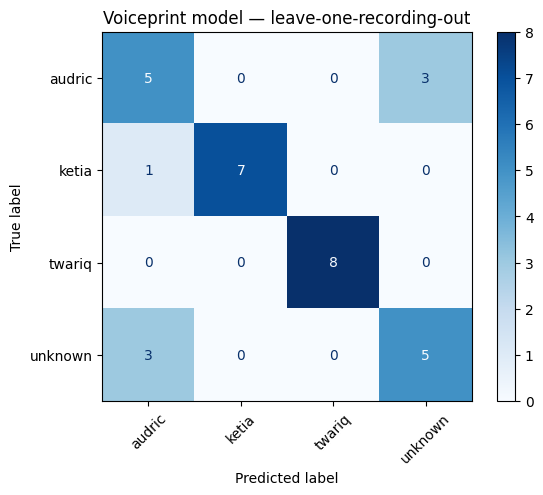

In [16]:
cm = confusion_matrix(y, oof_pred, labels=CLASSES)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=45)
plt.title("Voiceprint model — leave-one-recording-out")
plt.show()

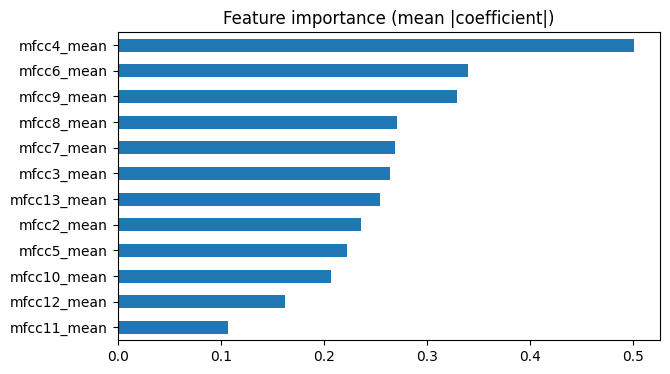

In [17]:
# Which MFCCs does the model rely on most? (fit on all clips)
# For logistic regression: average absolute coefficient across classes (features are standardized).
final_model = make_model("lr").fit(audio_features[MODEL_FEATURES].values, y)
importances = pd.Series(np.abs(final_model.named_steps["clf"].coef_).mean(axis=0), index=MODEL_FEATURES)
importances.sort_values().plot.barh(figsize=(7, 4), title="Feature importance (mean |coefficient|)")
plt.show()

**Interpretation.** Using only the MFCC 2–13 means lifted accuracy from 0.31–0.50 (all features) to 0.78, and log loss fell from about 1.0 to 0.64 — the extra features mostly added noise from phrase length, loudness and the augmentations.

The confusion matrix shows:
- **Twariq: 8/8 correct** and **Ketia: 7/8 correct** — these voices are distinct.
- **Audric and the outside voice are confused with each other** (3 clips each way). Their MFCC profiles are similar, which is also visible in the MFCC 2 boxplot.

With only 2 recordings per person the scores have high variance: one held-out recording is 4 of the 32 clips, so a single hard recording moves accuracy by about 12 points. More recordings per member — especially from Audric and from more outside voices — would make the model more reliable.

## 9. Verification logic and threshold
Predicting a name is not enough for security. The model always picks *someone*, even for a stranger. So access is **approved only if**:
1. the predicted label is a group member (not `unknown`), **and**
2. the model's confidence is at least `THRESHOLD`.

The table below shows, for the held-out predictions, how many members would be correctly approved and how many unauthorized clips would be wrongly let in at different thresholds.

In [18]:
conf = oof_proba.max(axis=1)
is_member = y != "unknown"
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    approved = (oof_pred != "unknown") & (conf >= t)
    correct_approve = (approved & is_member & (oof_pred == y)).sum()
    rows.append({
        "threshold": t,
        "members correctly approved": f"{correct_approve}/{is_member.sum()}",
        "wrong member approved": f"{(approved & is_member & (oof_pred != y)).sum()}/{is_member.sum()}",
        "unauthorized let in": f"{(approved & ~is_member).sum()}/{(~is_member).sum()}",
    })
display(pd.DataFrame(rows))
print(f"Threshold used in voice_model.py: {THRESHOLD}")

,threshold,members correctly approved,wrong member approved,unauthorized let in
0,0.3,20/24,1/24,3/8
1,0.4,18/24,1/24,3/8
2,0.5,14/24,1/24,3/8
3,0.6,11/24,0/24,2/8
4,0.7,8/24,0/24,0/8
5,0.8,6/24,0/24,0/8


Threshold used in voice_model.py: 0.7


**Chosen threshold: 0.70.** For a payment-approval system, letting a stranger in is much worse than asking a real member to repeat the phrase. At 0.70 none of the 8 unauthorized clips are approved and no member is mistaken for another, while 10 of 24 member clips pass on the first try. Lower thresholds approve more members but start letting the outside voice through (2–3 of 8).

## 10. Save the final model
The final model is trained on **all** clips and saved as `voice_model.joblib` together with the list of features it uses, so `verify_voice()` always extracts the same columns.

In [19]:
joblib.dump({"model": final_model, "feature_columns": MODEL_FEATURES}, "voice_model.joblib")
print("Saved voice_model.joblib")

Saved voice_model.joblib


## 11. Simulation: authorized vs unauthorized attempt
`verify_voice()` is the same function the CLI app will call. It loads the saved model, extracts features from a file and returns the decision.

Note: the files below were part of training, so they pass easily. For the system video, record **a new clip** of a member and of an outside voice and test those with the cell after this one.

In [20]:
def demo(path):
    member, confidence, approved = verify_voice(path)
    status = "✅ APPROVED" if approved else "⛔ ACCESS DENIED"
    print(f"{os.path.basename(path):30s} -> predicted {member:10s} (confidence {confidence:.2f})  {status}")

member_files = [os.path.join(AUDIO_DIR, r["file"]) for r in recordings if r["label"] != "unknown"]
unknown_files = [os.path.join(AUDIO_DIR, r["file"]) for r in recordings if r["label"] == "unknown"]

print("Authorized attempt:")
demo(member_files[0])
print("\nUnauthorized attempt:")
if unknown_files:
    demo(unknown_files[0])
else:
    print("No 'unknown_*' recording found — record a voice from outside the group to show this case.")

Authorized attempt:
audric_approve.m4a             -> predicted audric     (confidence 0.92)  ✅ APPROVED

Unauthorized attempt:
unknown1_approve.mp4           -> predicted unknown    (confidence 0.82)  ⛔ ACCESS DENIED


In [21]:
# Test a NEW recording (not used in training): upload it, then run this cell
# demo("audio_new/ketia_approve_test.wav")

## 12. Download outputs
These files go into the GitHub repo:
- `audio_features.csv`
- `voice_model.joblib`
- `voice_model.py`

In [22]:
try:
    from google.colab import files
    for f in ["audio_features.csv", "voice_model.joblib", "voice_model.py"]:
        files.download(f)
except ImportError:
    print("Not in Colab — the files are in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>